# Flujo y transporte conservativo: desnitrificación.

**Descripción**.

En esta notebook se plantea el problema de flujo de agua subterránea y transporte conservativo de la desnitrificación ...

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

# ESPECIES

|| $H^+$ | $Cl^-$ | $NO_3^-$ | $N_{2(aq)(p)}$ | $CH_2O_{(aq)}$ | $HCO_3^-$ |$O_{2(aq)}$ | $CO_3^{2-}$ |
|---|---|---|---|---|---|---|---|---|
|**initial**|1.e-07 | 1.e-16 | 1.e-05 | 1.e-16 | 1.e-05 | 0.001 | 1.e-06 | 4.69029e-07 |
|**inflow**|1e-08 | 0.001 | 0.001 | 1e-16 | 0.002 | 0.000537611 | 0.000252947 |2.52155e-06 |

# COMPONENTES
|| $H^+ - CO_3^{2-}$ | $Cl^-$ | $NO_3^-$ | $N_{2(aq)(p)}$ | $CH_2O_{(aq)}$ | $HCO_3^- - CO_3^{2-}$ |$O_{2(aq)}$ |
|---|---|---|---|---|---|---|---|
|**initial**|-3.69029e-07 | 1.e-16 | 1.e-05 | 1.e-16 | 1.e-05 | 0.00100047 | 1.e-06 |
|**inflow**| -2.51155e-06 | 0.001 | 0.001 | 1e-16 | 0.002 | 0.000540132 | 0.000252947 |

In [1]:
import os
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from time import perf_counter
import flopy
import xmf6

## ---> Módulos para las diferentes etapas del cálculo numérico
#from src_04 import gwf, lambdas, wma, vis
from src_02 import gwf, gwt, utils

In [2]:
#
# Variables de entorno
# -----
with open('../../env.json', 'r', encoding='utf-8') as file:
    env = json.load(file)
env["ROOT_DIR"] = os.getcwd() # Agregamos el dir raíz

xmf6.nice_print("Environment variables", env)

# --- DEFINICIÓN DE RUTAS Y ARCHIVOS ---

## ---> Diccionario con información de rutas y archivos
paths = dict(
    # Ejecutable de Modflow
    mf6_exe = env["MF6EXE"],
    mf6_dll = env["MF6DLL"],
    
    # Directorio de trabajo para WMA
    io_wma = os.path.join(env["ROOT_DIR"], "io_wma"),
    
    # Ejecutable "TR_1D_oper.exe"
    tr1d_exe = env["RT_WMA"],
    
    # Nombre de los modelos y espacios de trabajo  
    flow_name = "flow",
    flow_ws = "io_mf6/gwf",
    tran_name = "transport",
    tran_ws = "io_mf6/gwt",

    # Directorio de datos de salida
    dataviz = os.path.join(env["ROOT_DIR"], "dataviz"),

    # Archivo con las concentraciones iniciales de las componentes
    u_init = "u_init.dat",
)

## ---> Archivo para almacenar las proporciones de mezcla 
paths["wma_lambdas_filename"] = os.path.join(paths["io_wma"], 
                                             "input", "gypsum_eq", 
                                             "WMA_lambdas_gypsum_eq.dat")

## ---> Archivo requerido por "TR_1D_oper.exe"
paths["wma_workingDirectory_file"] = os.path.join(paths["io_wma"], "workingDirectory.txt")

## ---> Archivo de resultados del transporte reactivo
paths["gypsum_eq"] = os.path.join(paths["io_wma"], 'gypsum_eq.out')

## ---> Copia de los resultados del transporte reactivo para comparación
paths["gypsum_eq_copy"] = os.path.join(env["ROOT_DIR"], paths["dataviz"], "gypsum_eq_dfc.out")

## ---> Archivo con datos para comparación
paths["excel_data"] = os.path.join(env["ROOT_DIR"], paths["dataviz"], 'comparativa_02.xlsx')

xmf6.nice_print("Paths, filenames and more ...", paths)


Environment variables
―――――――――――――――――――――
  MF6EXE = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/mf6
  MF6DLL = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/libmf6.dll
  RT_WMA = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/TR_1D_oper.exe
  RT_COM = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/interfaz_remix.exe
ROOT_DIR = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\04_RT_WMA_denit7_1D\3_GWF_GWT_API_WMA_Denit
―――――――――――――――――――――

Paths, filenames and more ...
―――――――――――――――――――――――――――――
                  mf6_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/mf6
                  mf6_dll = C:/Users/luiggi/Documents/GitSites/RTWMA/bin/windows/libmf6.dll
                   io_wma = C:\Users\luiggi\Documents\GitSites\RTWMA\benchmarks\04_RT_WMA_denit7_1D\3_GWF_GWT_API_WMA_Denit\io_wma
                 tr1d_exe = C:/Users/luiggi/Documents/GitSites/RTWMA/benchmarks/00_RT_EXE/bin/TR_1D_oper.exe
                f

In [3]:
# Discretización del espacio
nlay, nrow, ncol = 1, 1, 30
delr, delc, delz = 1, 1, 1  #0.1, 1, 1 (dx,dy,dz)
dis = {
    'length_units' : "meters",
    'nlay': nlay, 
    'nrow': nrow, 
    'ncol': ncol,
    'delr': delr, 
    'delc': delc, 
    'top' : delz, 
    'botm': 0.0 
}
xmf6.nice_print("Spatial discretization", dis)

# Paso del tiempo
dt = 1.0e0
##NT = 40 #repeticiones del ciclo externo

# Discretización del tiempo para la simulación del flujo.
tdis_f = {
    'units': "days",
    'nper' : 1,
    'perioddata': [(dt, 1, 1.0)]
}
xmf6.nice_print("Time discretization: flow", tdis_f)

# Discretización del tiempo para la simulación del transporte.
tdis_t = {
    'units': "days",
    'nper' : 1,
    'perioddata': [(5, 500, 1.0)] # PERLEN, NSTP, TSMULT 
                                  # (5, 500, 1.0) = 5 dias, 100 pasos por dia 
}
xmf6.nice_print("Time discretization: transport", tdis_t)

#
# --- DATOS PARA LA SIMULACIÓN ---
#
components, species = utils.initial_conditions(paths, comp = True, spec=True)
ncomp = len(components["names"]) 
nspec = len(species["names"])

# Parámetros físicos.
phys = dict(
    initial_head = 1.0,
    bc_head_t1 =  {
        "pname": "CHD-1", 
        "stress_period_data": [[(0, 0, dis['ncol'] - 1), 1.0],],
    },
    porosity = 0.5,  # Porosity of mobile domain (unitless)
    hydraulic_conductivity = 1.0,  # Hydraulic conductivity ($cm s^{-1}$)
    specific_discharge = 0.2,  # inflow ($m d^{-1}$)
    longitudinal_dispersivity = 0.5, # 
    num_species = nspec,
    species = species["names"], # Components names
    spec_ext_concentration = species["ext_water"],  # Species Source concentration (unitless)
    spec_ini_concentration = species["init_conc"], # Species Initial concentration (unitless)
    num_components = ncomp,
    components = components["names"], # Components names
    comp_ext_concentration = components["ext_water"],  # Source concentration (unitless)
    comp_ini_concentration = components["init_conc"], # Initial concentration (unitless)   
)

# Agregamos la información del pozo para componente
q = phys["specific_discharge"] * dis['delc'] * (dis['top'] - dis['botm'])
for m in range(0, ncomp):
    phys[f"well_c{m+1}"] = {
        "pname": "WEL-1",
        "stress_period_data": [[(0, 0, 0), q, phys["spec_ext_concentration"][m]],],
        "auxiliary": ["CONCENTRATION"]
    }

xmf6.nice_print("Physical parameters", phys)

## ---> Diccionario para los parámetros numéricos
num = {
    "adv_scheme" : "TVD",
    "ims_flow" : {
        "complexity" : "SIMPLE",
        "outer_dvclose" : 1e-6,
        "inner_dvclose" : 1e-6,
    },
    "ims_tran" : {
        "complexity" : "SIMPLE",
        "linear_acceleration" : "BICGSTAB",
        "outer_dvclose" : 1e-8,
        "inner_dvclose" : 1e-8,
    },
}

xmf6.nice_print("Numerical parameters", num)


Spatial discretization
――――――――――――――――――――――
length_units = meters
        nlay = 1
        nrow = 1
        ncol = 30
        delr = 1
        delc = 1
         top = 1
        botm = 0.0
――――――――――――――――――――――

Time discretization: flow
―――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― data array ――
           = (1.0, 1, 1.0)
―――――――――――――――――――――――――

Time discretization: transport
――――――――――――――――――――――――――――――
     units = days
      nper = 1
perioddata = ―― data array ――
           = (5, 500, 1.0)
――――――――――――――――――――――――――――――

Physical parameters
―――――――――――――――――――
             initial_head = 1.0
               bc_head_t1 = {'pname': 'CHD-1', 'stress_period_data': [[(0, 0, 29), 1.0]]}
                 porosity = 0.5
   hydraulic_conductivity = 1.0
       specific_discharge = 0.2
longitudinal_dispersivity = 0.5
              num_species = 8
                  species = ―― data array ――
                          = h+
                          = cl-
    

In [5]:
# Seleccionamos una especie.
nombres_especies = dict(zip([str(i) for i in range(1, nspec+1)], species["names"]))
xmf6.nice_print("Selecciona una componente", nombres_especies)
m = int(input(" m = ")) - 1
print(m+1)

# --- PARA LA COMPONENTE SELECCIONADA ---
#
# Simulación de flujo
#
phys["well"] = phys[f"well_c{m+1}"]
o_sim_f, o_gwf = gwf.build(paths, tdis_f, phys, num, dis, silent = False)
o_sim_f.run_simulation(silent=True)

#
# Simulación de transporte
#

phys["initial_concentration"] = phys['spec_ini_concentration'][m][0]
phys["SSM"] = [(phys["well"]["pname"], 
               "AUX", 
               phys["well"]["auxiliary"][0]),]
o_sim_t, o_gwt = gwt.build(paths, tdis_t, phys, num, dis, silent = False)
print(f"-GWT: C{m+1}: {species["names"][m]}", end= " |")
o_sim_t.run_simulation(silent=True)


Selecciona una componente
―――――――――――――――――――――――――
1 = h+
2 = cl-
3 = no3-
4 = n2(aq)(p)
5 = ch2o(aq)
6 = hco3-
7 = o2(aq)
8 = co3-2
―――――――――――――――――――――――――


 m =  1


1
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model flow...
    writing model name file...
    writing package dis...
    writing package npf...
    writing package ic...
    writing package chd-1...
INFORMATION: maxbound in ('', 'chd', 'dimensions') changed to 1 based on size of stress_period_data
    writing package wel-1...
INFORMATION: maxbound in ('', 'wel', 'dimensions') changed to 1 based on size of stress_period_data
    writing package oc...
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model transport...
    writing model name file...
    writing package dis...
    writing package ic...
    writing package adv...
    writing package dsp...
    writing package mst...
    writing package fmi...
    writing package ssm...
    writing package oc...
-GWT: C1: h+ |

(True, [])

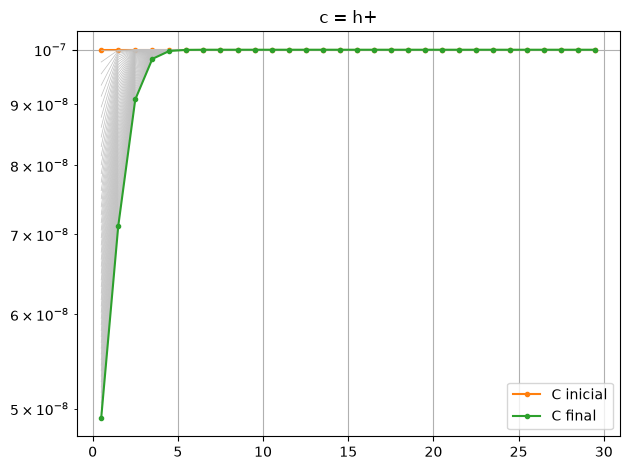

In [6]:
#
# ANALISIS y VISUALIZACIÓN
#

# Recuperamos las coordenadas del dominio
grid = o_gwt.modelgrid
x = grid.xcellcenters[0] # centros de los volúmenes

# Arreglo para la condición inicial
c_ini = np.full((nlay, nrow, ncol), phys['spec_ini_concentration'][m][0]) # En todo el dominio

# Objetos para recuperar la concentración c1
c_obj = o_gwt.output.concentration()

# Pasos de tiempo
times = np.asarray(c_obj.get_times())

# Condición inicial
c = np.empty((len(times)+1, len(x)), dtype=float)
c[0] = c_ini[0,0] # Condición inicial
c[1:] = c_obj.get_alldata()[:, 0, 0, :] # Todos los resultados

fig, ax = plt.subplots(1, 1)

ax.plot(x, c[0], lw=1.5, ls = "-", marker = ".", color='C1', label = "C inicial")

for ci in c[::10]:
    ax.plot(x, ci, lw=.5, color='silver')

ax.plot(x, c[-1], lw=1.5, ls = "-", marker = ".", color='C2',  label = "C final")

ax.set_title(f"c = {species["names"][m]}")
ax.set_yscale("log")
ax.grid()

ax.legend()

plt.tight_layout()
plt.show()